# Accumulation/Distribution Line + AutoEncoder Strategy

### 4.2.1. Overview

- The Accumulation/Distribution Line (A/D) with Autoencoder Strategy is a volume-based approach using the A/D Line and an Autoencoder to   - - detect anomalous price movements.
- A bullish signal triggers a long position when the A/D Line is rising with Autoencoder anomaly (reconstruction error > 0.05). A bearish - - signal triggers a short position when the A/D Line is falling. ATR sets TP/SL levels, optimized for 1-minute candles with 5x leverage.


### 4.2.1 Signal Generation

- Bullish: A/D Linet > A/D Line -1, Autoencoder reconstruction error > 0.05. Triggers long.
- Bearish: A/D Line < A/D Linet-1, Autoencoder reconstruction error > 0.05.Triggers short.
- Example: Price = $100, A/D Line rising, Autoencoder error = 0.06. Open long.




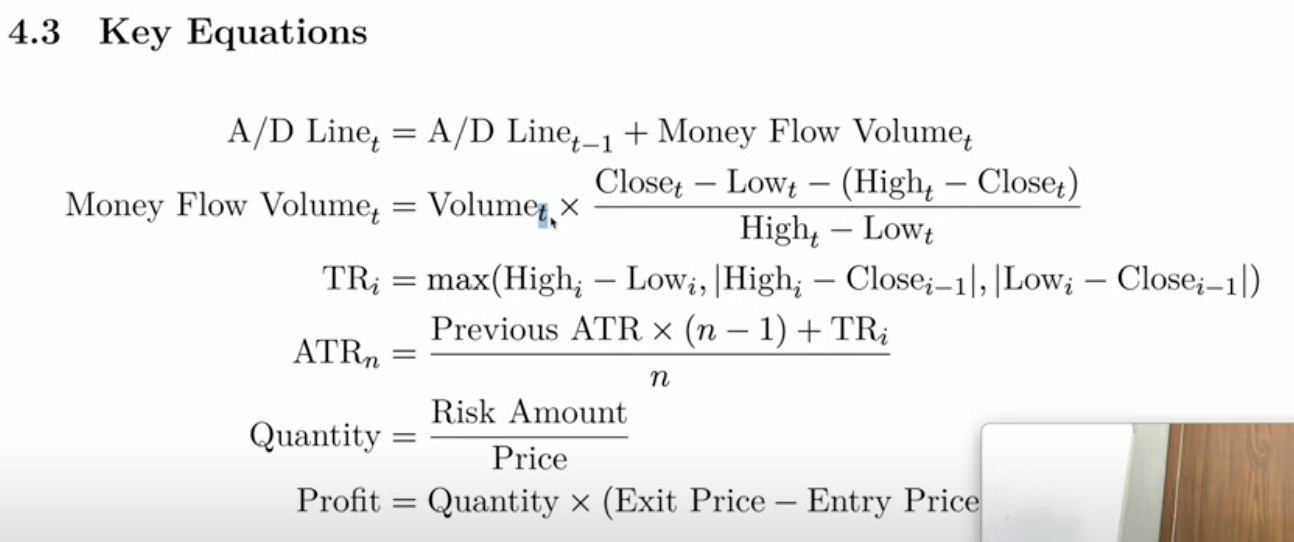

In [1]:
import ccxt.async_support as ccxt
import pandas as pd
import numpy as np
import asyncio
import os
import nest_asyncio
import logging
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        logging.FileHandler('trading_bot.log', mode='a'),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger(__name__)
nest_asyncio.apply()


In [2]:
SYMBOL = 'BNB/USDT'
TIMEFRAME = '15m'
RISK_AMOUNT = 2.0
LEVERAGE = 5
ATR_PERIOD = 14
TP_MULTIPLIER = 2.0
SL_MULTIPLIER = 1.0
FEE_RATE = 0.0002
MAX_POSITIONS = 2
CHECK_INTERVAL = 900
ERROR_THRESHOLD = 0.05

open_positions = []
scaler = StandardScaler()

In [3]:
# AutoEncoder Model
model = Sequential([
    Dense(16, activation='relu', input_shape=(4,)),
    Dense(8,  activation='relu'),
    Dense(4,  activation='relu'),
    Dense(2,  activation='relu'),    # bottleneck
    Dense(4,  activation='linear')   # reconstruct back to 4 features
])
model.compile(optimizer = 'adam' , loss = 'mse')


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [4]:
async def fetch_data(exchange , symbol :str  , timeframe : str , limit : int = 100) -> pd.DataFrame:
    try:
        ohlcv = await exchange.fetch_ohlcv(symbol , timeframe , limit = limit)
        df = pd.DataFrame(ohlcv , columns = ['timestamp' , 'open' , 'high','low','close','volume'])
        df['timestamp'] = pd.to_datetime(df['timestamp'] , unit = 'ms')
        return df
    except Exception as e:
        logger.error(f"Error Fetching data: {str(e)}")
        return pd.DataFrame

In [5]:
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    try:
        # Accumulation / Distribution Line
        df['money_flow_multiplier'] = ((df['close'] - df['low']) - (df['high'] - 
                                        df['close'])) / (df['high'] - df['low'])
        df['money_flow_volume'] = df['money_flow_multiplier'] * df['volume']
        df['ad_line' ] = df['money_flow_volume'].cumsum() # ad_line -> Accumulation and Distribution Line

        # ATR
        df['tr'] = pd.concat([df['high'] - df['low'],
                             (df['high'] - df['close'].shift()).abs(),
                             (df['low'] - df['close'].shift()).abs()
                             ], axis = 1).max(axis = 1)
        df['atr'] = df['tr'].rolling(ATR_PERIOD).mean()

        # Features
        df['price_change'] = df['close'].pct_change()
        df['ad_change'] = df['ad_line'].pct_change()
        df['volume_change'] = df['volume'].pct_change()
        return df.dropna(subset=['price_change','ad_change','atr','volume_change'])
    except Exception as e:
        logger.error(f"Error calculating indicators: {str(e)}")
        return df
        
        

In [6]:
def train_model(df: pd.DataFrame) -> None:
    try:
        features = ['price_change' , 'ad_change' , 'atr', 'volume_change']
        X = df[features].dropna()
        if len(X) < 10:
            return 
        X_scaled = scaler.fit_transform(X)
        model.fit(X_scaled , X_scaled , epochs = 50 , verbose = 0)
    except Exception as e:
        logger.error(f"Error training model : {str(e)}")

In [7]:
def get_ad_signal(df: pd.DataFrame) -> str:
    try:
        ad_line = df['ad_line'].iloc[-1]
        ad_line_prev = df['ad_line'].iloc[-2]
        if pd.isna([ad_line , ad_line_prev]).any():
            return 'neutral'
        features = ['price_change' , 'ad_change','atr','volume_change']
        X = df[features].iloc[-1:].dropna()
        if X.empty:
            return 'neutral'
        X_scaled = scaler.transform(X)
        X_pred = model.predict(X_scaled , verbose = 0) # verbose -> basically , shows how much progress information (e.g. bar , etc)
        error = np.mean((X_scaled - X_pred) **2 )
        if ad_line > ad_line_prev and error > ERROR_THRESHOLD:
            return 'bullish'
        if ad_line < ad_line_prev and error > ERROR_THRESHOLD:
            return 'bearish'
    except Exception as e:
        logger.error(f"Error in signal generation: {str(e)}")
        

In [8]:
async def manage_positions(exchange , current_price : float ):
    global open_positions
    positions_to_remove = []
    try:
        for pos in open_positions:
            entry_price = pos['entry_price']
            qty = pos['quantity']
            side = pos['side']
            tp_price = pos['tp_price']
            sl_price = pos['sl_price']
            if side == 'long':
                if current_price >= tp_price:
                    logger.info(f"[check mark] Long TP hit at {current_price: .2f} , Profit:{(current_price - entry_price) * qty *  LEVERAGE:.2f}")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
                elif current_price <= sl_price:
                    logger.info(f"[cross mark] Long SL hit at {current_price: .2f} , Loss: {(entry_price - current_price) * qty *  LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
            else:
                if current_price <= tp_price:
                    logger.info(f"[check mark] Short TP hit at {current_price: .2f} , Profit: {( entry_price - current_price) * qty *  LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
                elif current_price >= sl_price:
                    logger.info(f"[cross mark] Short SL hit at {current_price: .2f} , Loss:{(current_price - entry_price) * qty  * LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
        open_positions = [pos for pos in open_positions if pos not in positions_to_remove]
    except Exception as e:
        logger.error(f"Error managing the Positions: {str(e)}")

                
                    

In [9]:
async def place_order(exchange , signal: str , price : float , atr:float ):
    try:
        if len(open_positions) >= MAX_POSITIONS:
            logger.info("Max positions reached, skipping new order")
            return
        qty = RISK_AMOUNT / price
        if signal == 'bullish':
            order = await exchange.create_market_buy_order(SYMBOL ,qty )
            tp_price = price + TP_MULTIPLIER * atr;
            sl_price = price - SL_MULTIPLIER * atr;
            open_positions.append({
                'symbol' :SYMBOL , 
                'side' : 'long',
                'entry_price' : price,
                'quantity' : qty,
                'tp_price' : tp_price , 
                'sl_price' : sl_price
            })
            logger.info(f"[char increasing] Opened long at {price:. 2f} , Qty: {qty:.4f} , TP: {tp_price:. 2f} , SL: {sl_price:. 2f}")
        elif signal == 'bearsih':
            order = await exchange.create_market_sell_order(SYMBOL ,qty )
            tp_price = price - TP_MULTIPLIER * atr;
            sl_price = price + SL_MULTIPLIER * atr;
            open_positions.append({
                'symbol' : SYMBOL , 
                'side' : 'short',
                'entry_price' : price,
                'quantity' : qty,
                'tp_price' : tp_price , 
                'sl_price' : sl_price
            })
            logger.info(f"[char increasing] Opened short at {price:. 2f} , Qty: {qty:.4f} , TP: {tp_price:. 2f} , SL: {sl_price:. 2f}")
    except Exception as e:
        logger.error(f"Error placing order: {str(e)}")
            
            
            

In [10]:
async def main():
    try:
        from dotenv import load_dotenv
        load_dotenv('test.env')

        api_key = os.environ['BINANCE_API_KEY_TEST']
        api_secret = os.environ['BINANCE_API_SECRET_TEST']

        exchange = ccxt.binance({
            'enableRateLimit': True,
            'apiKey':  api_key,
            'secret': api_secret,
            "options": { "defaultType": "future" }
            
        })
        await exchange.load_markets()
        await exchange.set_leverage(LEVERAGE , SYMBOL)
        df_initial = await fetch_data(exchange , SYMBOL , TIMEFRAME ,limit = 500)
        if not df_initial.empty:
            df_initial = calculate_indicators(df_initial)
            train_model(df_initial)
        while True:
            try:
                df = await fetch_data(exchange , SYMBOL , TIMEFRAME )
                if df.empty:
                    await asyncio.sleep(CHECK_INTERVAL)
                    continue
                df = calculate_indicators(df)
                current_price = df['close'].iloc[-1]
                atr = df['atr'].iloc[-1]
                signal = get_ad_signal(df)
                await manage_positions(exchange , current_price)
                if signal != 'neutral':
                    await place_order(exchange , signal , current_price , atr )
                logger.info(f"Price: {current_price:.2f} , A/D Line : {df["ad_line"].iloc[-1]:.2f} , Signal: {signal}")
                if len(df) >= 500:
                    train_model(df)
                await asyncio.sleep(CHECK_INTERVAL)
            except Exception as e:
                logger.error(f"Error in main loop: {str(e)}")
                await asyncio.sleep(CHECK_INTERVAL)
    except Exception as e:
        logger.error(f"Error initializing exchange: {str(e)}")
    finally:
        if exchange is not None:
            await exchange.close()
            logger.info("Exchange connection closed.")
        

In [ ]:
if __name__ == "__main__":
   asyncio.run(main())